# Baseline YOLOv8 model: invasive plant detection (Group 9)

Classes (master list, do not change): 0 fireweed, 1 himalayan_balsam, 2 japanese_knotweed, 3 purple_loosestrife

**Baseline hyperparameters (teammates change ONE of these, 3 different values each):**

| Parameter | Baseline value |
|---|---|
| model | yolov8n.pt (COCO pretrained) |
| epochs | 50 |
| imgsz | 640 |
| batch | 16 |
| lr0 | 0.01 |
| optimizer | SGD |
| seed | 0 |

Before running: Runtime -> Change runtime type -> **T4 GPU**.
Drive layout expected: `MyDrive/IAT360CVProject/dataset/` containing `dataset_out.zip`, `images/test/`, `labels/test/`, `data.yaml`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. Unzip training/val data onto Colab's local disk (much faster than training from Drive)

In [7]:
import zipfile, os, shutil

DRIVE_DIR = "/content/drive/MyDrive/IAT360CVProject/dataset"
LOCAL_DIR = "/content/dataset"

shutil.rmtree(LOCAL_DIR, ignore_errors=True)
os.makedirs(LOCAL_DIR)

# Extract manually and fix Windows backslashes (Compress-Archive on Windows can leave them in the names)
with zipfile.ZipFile(f"{DRIVE_DIR}/dataset_out.zip") as z:
    for m in z.infolist():
        name = m.filename.replace("\\", "/")
        if name.endswith("/"):
            continue
        target = os.path.join(LOCAL_DIR, name)
        os.makedirs(os.path.dirname(target), exist_ok=True)
        with z.open(m) as src, open(target, "wb") as dst:
            shutil.copyfileobj(src, dst)

# Copy our 90 test photos + labels from Drive
for kind in ["images", "labels"]:
    shutil.copytree(f"{DRIVE_DIR}/{kind}/test", f"{LOCAL_DIR}/{kind}/test")

print(os.listdir(LOCAL_DIR))

['labels', 'images']


## 2. Write data.yaml for the local copy

In [8]:
yaml_text = '''path: /content/dataset
train: images/train
val: images/val
test: images/test

names:
  0: fireweed
  1: himalayan_balsam
  2: japanese_knotweed
  3: purple_loosestrife
'''
open("/content/dataset/data.yaml", "w").write(yaml_text)
print(yaml_text)

path: /content/dataset
train: images/train
val: images/val
test: images/test

names:
  0: fireweed
  1: himalayan_balsam
  2: japanese_knotweed
  3: purple_loosestrife



## 3. Sanity checks (do not skip: catches wrong class ids and missing files)

In [6]:
import glob, os
imgs = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob("/content/dataset/images/test/*.*")}
lbls = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob("/content/dataset/labels/test/*.txt")}
print(sorted(imgs - lbls))

['purple_loosestrife_11_jpg.rf.e3bec6ec0de41488f5a90f9f1450cf3d', 'purple_loosestrife_12_jpg.rf.1ec7eae2ba45ec4040d388914a3fb1de', 'purple_loosestrife_13_jpg.rf.e087acd5825de826fee2f2cb40ba7eb5', 'purple_loosestrife_14_jpg.rf.617c7f1fd21ac2bfd4f44434b4fab752', 'purple_loosestrife_15_jpg.rf.6e2e926c960e456d135dd5d4f8a06a87']


In [9]:
import glob, os
from collections import Counter

NAMES = {0:"fireweed", 1:"himalayan_balsam", 2:"japanese_knotweed", 3:"purple_loosestrife"}

for split in ["train", "val", "test"]:
    imgs = glob.glob(f"/content/dataset/images/{split}/*.*")
    lbls = glob.glob(f"/content/dataset/labels/{split}/*.txt")
    img_stems = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
    lbl_stems = {os.path.splitext(os.path.basename(p))[0] for p in lbls}
    boxes, imgs_with = Counter(), Counter()
    bad_ids = 0
    for l in lbls:
        ids = set()
        for line in open(l):
            p = line.split()
            if not p: continue
            c = int(p[0])
            if c not in NAMES: bad_ids += 1
            boxes[c] += 1; ids.add(c)
        for c in ids: imgs_with[c] += 1
    print(f"--- {split}: {len(imgs)} images, {len(lbls)} labels")
    print("   images without label:", len(img_stems - lbl_stems), "| labels without image:", len(lbl_stems - img_stems), "| bad class ids:", bad_ids)
    print("   images per class:", {NAMES[c]: imgs_with[c] for c in sorted(imgs_with)})
    print("   boxes per class: ", {NAMES[c]: boxes[c] for c in sorted(boxes)})

--- train: 5493 images, 5493 labels
   images without label: 0 | labels without image: 0 | bad class ids: 0
   images per class: {'fireweed': 1019, 'himalayan_balsam': 2753, 'japanese_knotweed': 2609, 'purple_loosestrife': 228}
   boxes per class:  {'fireweed': 1416, 'himalayan_balsam': 9942, 'japanese_knotweed': 22836, 'purple_loosestrife': 234}
--- val: 459 images, 459 labels
   images without label: 0 | labels without image: 0 | bad class ids: 0
   images per class: {'fireweed': 99, 'himalayan_balsam': 218, 'japanese_knotweed': 136, 'purple_loosestrife': 57}
   boxes per class:  {'fireweed': 141, 'himalayan_balsam': 486, 'japanese_knotweed': 911, 'purple_loosestrife': 58}
--- test: 90 images, 90 labels
   images without label: 0 | labels without image: 0 | bad class ids: 0
   images per class: {'fireweed': 15, 'himalayan_balsam': 25, 'japanese_knotweed': 26, 'purple_loosestrife': 24}
   boxes per class:  {'fireweed': 89, 'himalayan_balsam': 63, 'japanese_knotweed': 30, 'purple_loose

Expected: train about 5,493 images, val about 459, test 90. **Bad class ids must be 0.**
Check that the test set contains all four classes. A class with no test images gets no meaningful test score.

## 4. Train the baseline

In [10]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # pretrained COCO weights = transfer learning

results = model.train(
    data="/content/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    lr0=0.01,
    optimizer="SGD",
    seed=0,
    project="/content/drive/MyDrive/IAT360CVProject/runs",   # saved to Drive so it survives a disconnect
    name="baseline",
    exist_ok=True,
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optimize

## 5. Evaluate on OUR 90 test photos (the baseline score you report)

In [11]:
best = YOLO("/content/drive/MyDrive/IAT360CVProject/runs/baseline/weights/best.pt")
metrics = best.val(
    data="/content/dataset/data.yaml",
    split="test",
    project="/content/drive/MyDrive/IAT360CVProject/runs",
    name="baseline_test",
    exist_ok=True,
    plots=True,
)

print("mAP50:     ", round(metrics.box.map50, 4))
print("mAP50-95:  ", round(metrics.box.map, 4))
print("Precision: ", round(metrics.box.mp, 4))
print("Recall:    ", round(metrics.box.mr, 4))

print("\nPer-class (mAP50-95):")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"  {metrics.names[int(c)]:20s} {metrics.box.maps[int(c)]:.4f}")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3957.5±1512.2 MB/s, size: 453.6 KB)
val: Scanning /content/dataset/labels/test... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 2.2Kit/s 0.0s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.3it/s 4.6s
                   all         90        285      0.215      0.224      0.128      0.044
              fireweed         15         89      0.303       0.18      0.176     0.0574
      himalayan_balsam         25         63       0.35      0.286      0.224     0.0674
     japanese_knotweed         26         30     0.0263      0.333     0.0677     0.0388
    purple_loosestrife         24        103      0.178     0.0971      0.044     0.0122


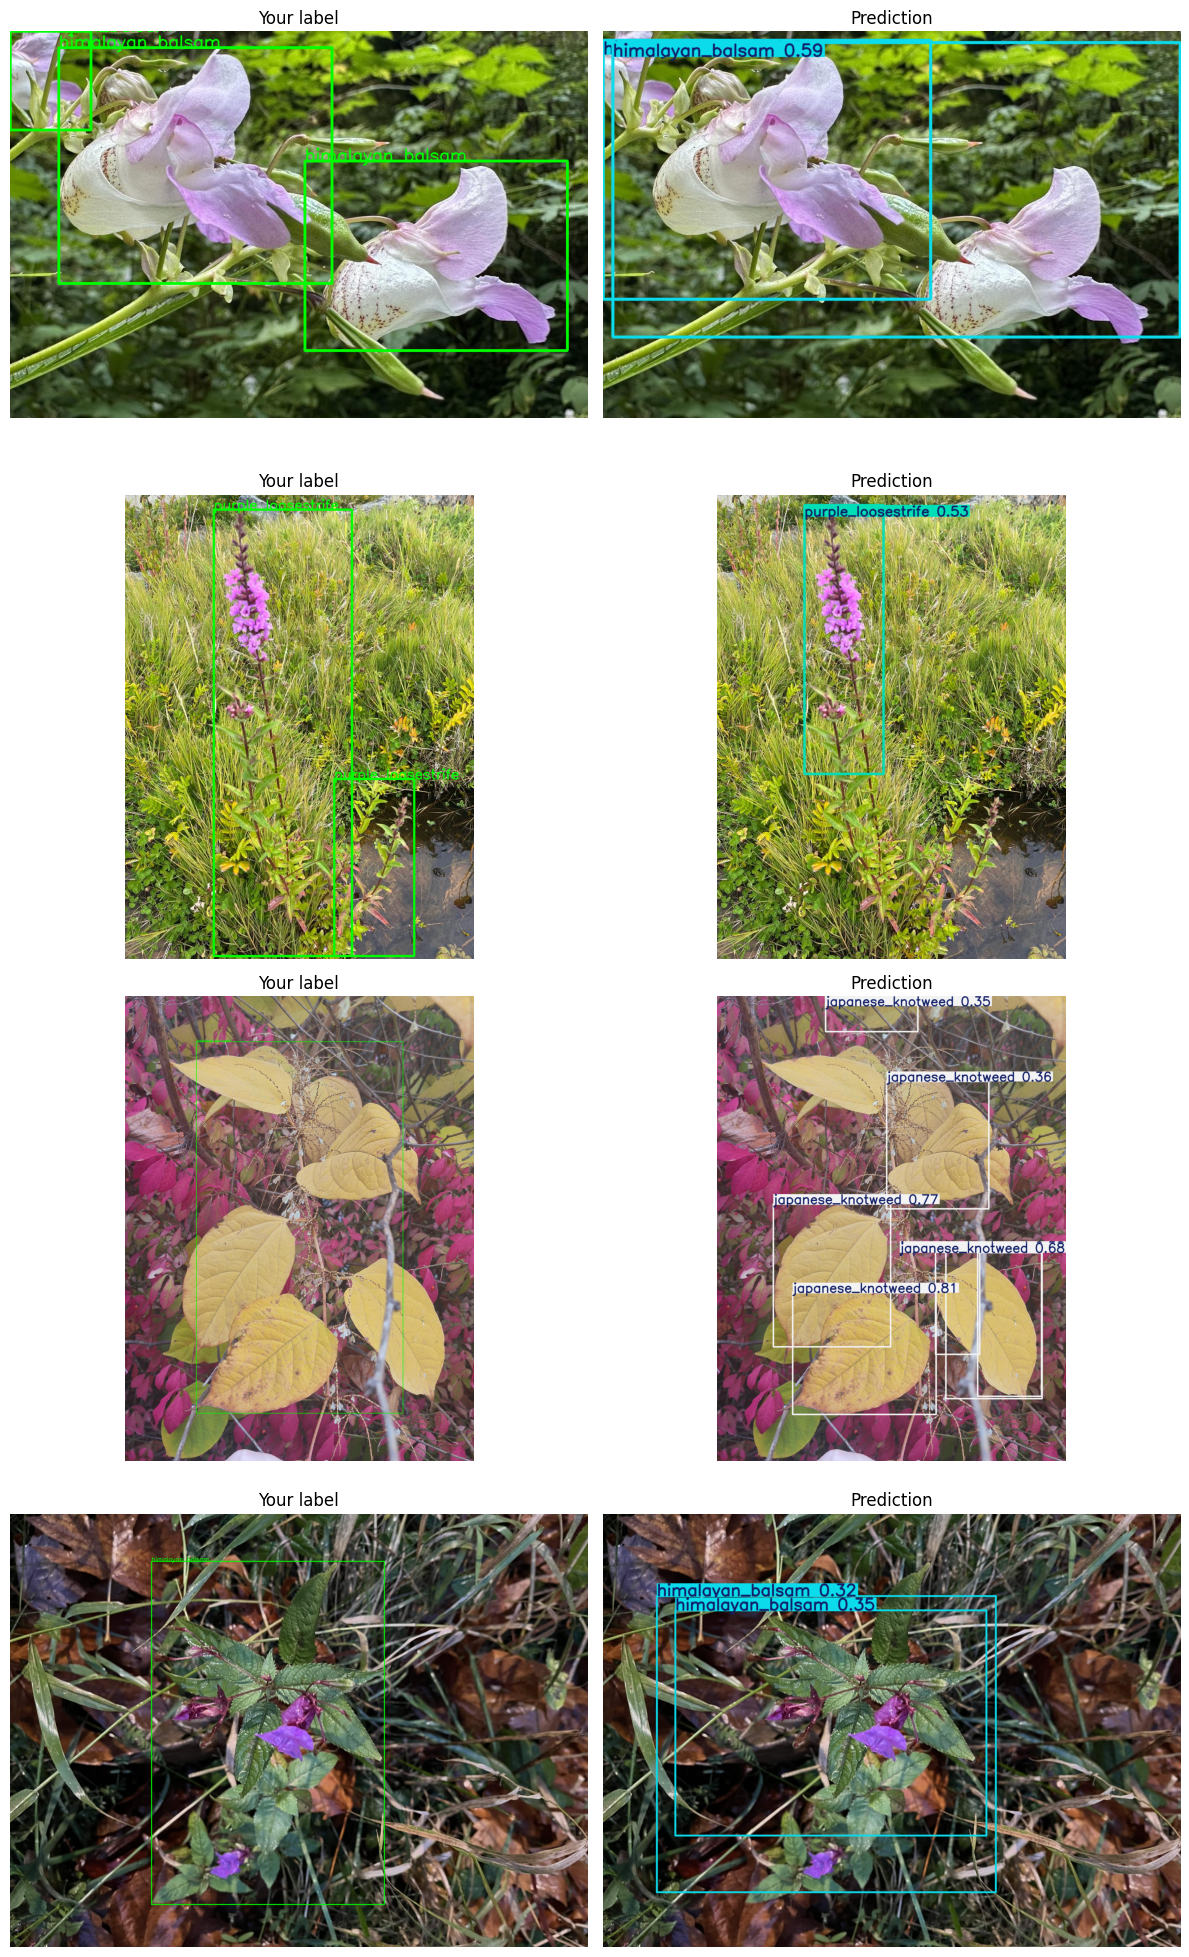

In [12]:
import glob, random, cv2
import matplotlib.pyplot as plt

random.seed(1)
imgs = random.sample(sorted(glob.glob("/content/dataset/images/test/*.*")), 4)
names = {0:"fireweed", 1:"himalayan_balsam", 2:"japanese_knotweed", 3:"purple_loosestrife"}

fig, axes = plt.subplots(len(imgs), 2, figsize=(12, 5 * len(imgs)))
for row, p in enumerate(imgs):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    gt = im.copy()
    lbl = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for l in open(lbl):
        c, x, y, bw, bh = l.split()
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        p1, p2 = (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2))
        cv2.rectangle(gt, p1, p2, (0, 255, 0), 3)
        cv2.putText(gt, names[int(c)], p1, cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    pred = best.predict(p, conf=0.25, verbose=False)[0].plot()
    pred = cv2.cvtColor(pred, cv2.COLOR_BGR2RGB)
    axes[row, 0].imshow(gt);   axes[row, 0].set_title("Your label");  axes[row, 0].axis("off")
    axes[row, 1].imshow(pred); axes[row, 1].set_title("Prediction");  axes[row, 1].axis("off")
plt.tight_layout(); plt.show()

## 6. Save metrics and example predictions for the report

In [13]:
import json

out = {
    "run": "baseline",
    "hyperparameters": {"model":"yolov8n.pt","epochs":50,"imgsz":640,"batch":16,"lr0":0.01,"optimizer":"SGD","seed":0},
    "test_metrics": {
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "per_class_mAP50-95": {metrics.names[int(c)]: float(metrics.box.maps[int(c)]) for c in metrics.box.ap_class_index},
    },
}
json.dump(out, open("/content/drive/MyDrive/IAT360CVProject/runs/baseline_metrics.json", "w"), indent=2)
print(json.dumps(out, indent=2))

# example predictions on test photos (for the 'shortcomings' section)
best.predict("/content/dataset/images/test", save=True, conf=0.25,
             project="/content/drive/MyDrive/IAT360CVProject/runs", name="baseline_predictions", exist_ok=True)

{
  "run": "baseline",
  "hyperparameters": {
    "model": "yolov8n.pt",
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "lr0": 0.01,
    "optimizer": "SGD",
    "seed": 0
  },
  "test_metrics": {
    "mAP50": 0.12800934505280795,
    "mAP50-95": 0.043968584131994545,
    "precision": 0.21453632463228103,
    "recall": 0.22397756964681803,
    "per_class_mAP50-95": {
      "fireweed": 0.05740800676059925,
      "himalayan_balsam": 0.06744993731822098,
      "japanese_knotweed": 0.03880241882254547,
      "purple_loosestrife": 0.01221397362661251
    }
  }
}

image 1/90 /content/dataset/images/test/10_japanese_knotweed_jpg.rf.7f09bb3b71ad1974d2fa44473b68c51f.jpg: 480x640 5 japanese_knotweeds, 10.3ms
image 2/90 /content/dataset/images/test/11_japanese_knotweed_jpg.rf.44240bad05cdef09fa7f83a33fe796ef.jpg: 480x640 2 japanese_knotweeds, 10.5ms
image 3/90 /content/dataset/images/test/12_japanese_knotweed_jpg.rf.d358a0501ea21f41f5f6dcee6ffe44ca.jpg: 640x480 7 japanese_knotweeds, 13.0

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'fireweed', 1: 'himalayan_balsam', 2: 'japanese_knotweed', 3: 'purple_loosestrife'}
 obb: None
 orig_img: array([[[145, 198, 231],
         [142, 195, 228],
         [139, 192, 225],
         ...,
         [125, 167, 142],
         [129, 169, 144],
         [127, 167, 142]],
 
        [[147, 200, 233],
         [144, 197, 230],
         [142, 195, 228],
         ...,
         [128, 170, 145],
         [130, 170, 145],
         [126, 166, 141]],
 
        [[149, 202, 235],
         [147, 200, 233],
         [145, 198, 231],
         ...,
         [130, 172, 147],
         [129, 169, 144],
         [123, 163, 138]],
 
        ...,
 
        [[ 56,  63,  90],
         [ 57,  64,  91],
         [ 56,  63,  90],
         ...,
         [123, 190, 191],
         [122, 189, 190],
         [120, 187, 188]],
 
        [[ 55,  62,  89

In [ ]:
import glob
from collections import Counter

names = {0:"fireweed", 1:"himalayan_balsam", 2:"japanese_knotweed", 3:"purple_loosestrife"}
hit, total, pred_boxes, gt_boxes = Counter(), Counter(), Counter(), Counter()

for p in sorted(glob.glob("/content/dataset/images/test/*.*")):
    lbl = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    gt = [int(l.split()[0]) for l in open(lbl) if l.strip()]
    main = Counter(gt).most_common(1)[0][0]
    pred = [int(c) for c in best.predict(p, conf=0.25, verbose=False)[0].boxes.cls.tolist()]
    total[main] += 1
    hit[main] += main in pred
    gt_boxes.update(gt)
    pred_boxes.update(pred)

for c, n in names.items():
    print(f"{n:20s} right class in {hit[c]}/{total[c]} photos | boxes labeled {gt_boxes[c]} vs predicted {pred_boxes[c]}")
print("Overall:", sum(hit.values()), "/", sum(total.values()))

## 7. After it finishes

Everything is in `MyDrive/IAT360CVProject/runs/`:
- `baseline/weights/best.pt`, `baseline/results.png` (training curves)
- `baseline_test/` (confusion matrix, PR curve on the test set)
- `baseline_metrics.json`, `baseline_predictions/`

Download these, put them in the `baseline` branch of the repo, and send teammates the hyperparameter table above.